# Model Experiments: Poisson, Hawkes, Neural Hawkes, LogNormMix

Loads every source once, fits each of the four models per source, and
builds a comparison table/plot at the end. Model-specific logic lives in
`models/<name>/model.py` + `models/<name>/dataloader.py`; this notebook is
orchestration + comparison only — see `common/` and `features/` for the
shared preprocessing those dataloaders build on.

**Sections**
1. Setup & data loading (once)
2. Poisson baseline
3. Hawkes baseline
4. Neural Hawkes Process
5. LogNormMix
6. Cross-model comparison


In [2]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

from arrivalcast.data.io import load_all_sources

pd.set_option("display.max_columns", None)
%matplotlib inline


## 1. Load data once

`load_all_sources()` returns `dict[source_id] -> DataFrame`, tagged with
`.attrs["dataset"]` ("synthetic" or "bts") and `.attrs["pattern_description"]`.
Re-run this cell only if the underlying data changes — every section below
reuses `sources` rather than re-reading from disk.

In [3]:
sources = load_all_sources(
    synthetic_path="../data/synthetic",
    # bts_path="../data/bts/DL_JFK-LAX.parquet",
)
print(f"Loaded {len(sources)} sources")
pd.Series({sid: (df.attrs["dataset"], len(df)) for sid, df in sources.items()}).head(10)


Loaded 26 sources


SRC_01      (synthetic, 731)
SRC_02      (synthetic, 731)
SRC_03      (synthetic, 522)
SRC_04       (synthetic, 24)
SRC_05        (synthetic, 8)
SRC_06      (synthetic, 313)
SRC_07      (synthetic, 500)
SRC_08    (synthetic, 17544)
SRC_09     (synthetic, 2924)
SRC_10     (synthetic, 1044)
dtype: object

### Observation window cutoff

`study_end` (the actual end of the observation period) must be your real dataset cutoff, not the last observed event — using the last event silently drops the right-censored "quiet tail" after it, which biases every model (worst case: a sparse source's test split can end up with `total_hours = 0`, e.g. SRC_05's quarterly test split). **Set this to the actual generation/extraction cutoff for your data** and every dataloader below will use it for the final (test) split.

In [4]:
GLOBAL_STUDY_END = pd.Timestamp("2025-01-01")  # <- set to your real cutoff (synthetic generation end / BTS extraction date)

A results table is accumulated across every model section below —
each section appends its per-source metrics rather than overwriting, so
Section 6 can compare all four side by side without re-fitting anything.

In [5]:
results = []  # list of dicts: source_id, model, test_log_likelihood, ...


## 2. Poisson baseline

Homogeneous Poisson: fit rate on train, evaluate log-likelihood on test.
No covariates — see `models/poisson/model.py` docstring for why.

In [10]:
from arrivalcast.models.poisson.dataloader import PoissonDataLoader
from arrivalcast.models.poisson.model import HomogeneousPoisson

for source_id, df in sources.items():
    loader = PoissonDataLoader(df["arrival_timestamp"], global_study_end=GLOBAL_STUDY_END)
    splits = loader.get_splits()
    train, test = splits["train"], splits["test"]
    if train.n_events < 2 or test.n_events == 0:
        continue

    t0 = time.time()
    model = HomogeneousPoisson().fit(train.n_events, train.total_hours)
    test_ll = model.log_likelihood(test.n_events, test.total_hours)
    secs = round(time.time() - t0, 1)

    results.append({
        "source_id": source_id,
        "dataset": df.attrs["dataset"],
        "model": "Poisson",
        "test_log_likelihood": test_ll,
        "test_ll_per_event": test_ll / max(test.n_events, 1),
        "predicted_next_gap_hrs": model.predict_next_gap_hours(),
        "train_seconds": secs
    })

poisson_results = pd.DataFrame(
    [r for r in results if r["model"] == "Poisson"]
)
print(poisson_results["train_seconds"].median())
print(f"Fitted Poisson for {sum(r['model']=='Poisson' for r in results)} sources")


0.0
Fitted Poisson for 125 sources


## 3. Hawkes baseline

Exponential-kernel Hawkes via multi-start MLE (see `models/hawkes/model.py`
— single-start Nelder-Mead converges to a spurious no-self-excitation local
optimum on roughly half of naive starting points, so `.fit()` restarts from
several points by default and keeps the best).

In [11]:
from arrivalcast.models.hawkes.dataloader import HawkesDataLoader
from arrivalcast.models.hawkes.model import HawkesExponential

for source_id, df in sources.items():
    loader = HawkesDataLoader(df["arrival_timestamp"], global_study_end=GLOBAL_STUDY_END)
    splits = loader.get_splits()
    train, test = splits["train"], splits["test"]
    if len(train.gaps_hours) < 5 or len(test.gaps_hours) == 0:
        continue

    t0 = time.time()
    model = HawkesExponential().fit(train.gaps_hours, train.total_hours)
    test_ll = model.log_likelihood(test.gaps_hours, test.total_hours)
    secs = round(time.time() - t0, 1)

    results.append({
        "source_id": source_id,
        "dataset": df.attrs["dataset"],
        "model": "Hawkes",
        "test_log_likelihood": test_ll,
        "test_ll_per_event": test_ll / max(len(test.gaps_hours), 1),
        "mu": model.params.mu,
        "alpha": model.params.alpha,
        "beta": model.params.beta,
        "branching_ratio": model.params.branching_ratio,
        "train_seconds": secs
    })

hawkes_results = pd.DataFrame(
    [r for r in results if r["model"] == "Hawkes"]
)
print(hawkes_results["train_seconds"].median())
print(f"Fitted Hawkes for {sum(r['model']=='Hawkes' for r in results)} sources")


1.65
Fitted Hawkes for 24 sources


## 4. Neural Hawkes Process

Requires `torch`. Trained per-source (or batch several sources together via
`pad_batch` — recommended once sequence lengths are grouped by similar
magnitude, since padding SRC_08's 17.5k events against SRC_23's 2 wastes
almost all compute on padding). This section shows the single-source path;
swap in `pad_batch` + a DataLoader for batched training.

In [7]:
import torch
from arrivalcast import training as T  # shared training loops (also used by arrivalcast run)

torch.set_num_threads(1)
print("max epochs:", T.MAX_EPOCHS, "| patience:", T.PATIENCE, "| lr:", T.LR)

max epochs: 200 | patience: 20 | lr: 0.01


In [8]:
# Training now lives in training.py (train_nhp_one_source), so the notebook and
# arrivalcast run train identical models. Changes vs. the first pass:
#   - early stopping on the validation split (best-validation weights kept),
#     up to T.MAX_EPOCHS full-batch steps instead of a fixed 50
#   - seeded per source for reproducibility
#   - Time2Vec gets gaps scaled by the train median gap; intensity bias starts
#     at the train arrival rate (NeuralHawkes.init_from_train_gaps)
train_nhp_one_source = T.train_nhp_one_source

In [9]:
trained_nhp_models = {}  # source_id -> (model, time2vec), for Section 7
nhp_train_log = []

for source_id, df in sources.items():
    out = train_nhp_one_source(df, GLOBAL_STUDY_END)
    if out is None:
        continue
    test_ll, n_test_events, nhp_model, nhp_time2vec, info = out
    trained_nhp_models[source_id] = (nhp_model, nhp_time2vec)
    nhp_train_log.append({"source_id": source_id, **info})
    results.append({
        "source_id": source_id,
        "dataset": df.attrs["dataset"],
        "model": "NeuralHawkes",
        "test_log_likelihood": test_ll,
        "test_ll_per_event": test_ll / max(n_test_events, 1),
    })

print(f"Fitted NeuralHawkes for {sum(r['model']=='NeuralHawkes' for r in results)} sources")

Fitted NeuralHawkes for 25 sources


## 5. LogNormMix

Also requires `torch`. Same per-source training loop shape as Section 4 —
no Monte Carlo integration needed here (that's the "intensity-free" part),
so this trains faster than NHP for the same number of epochs.

In [10]:
# LogNormMix training also lives in training.py (train_lnm_one_source). Changes:
#   - sigma upper bound lowered from e^5 (~148) to e^1 (~2.7) on the log scale
#     (the old bound made CRPS ~1e117 on every source)
#   - log-gap input standardized with train statistics; component locations
#     start at the train mean log-gap
#   - early stopping on the validation split, seeded per source
#   - no longer requires >= 2 TEST gaps to train (old gate skipped SRC_05)
train_lnm_one_source = T.train_lnm_one_source

In [11]:
trained_lnm_models = {}  # source_id -> model, for Section 7
lnm_train_log = []

for source_id, df in sources.items():
    out = train_lnm_one_source(df, GLOBAL_STUDY_END)
    if out is None:
        continue
    test_ll, n_predicted_gaps, lnm_model, info = out
    trained_lnm_models[source_id] = lnm_model
    lnm_train_log.append({"source_id": source_id, **info})
    results.append({
        "source_id": source_id,
        "dataset": df.attrs["dataset"],
        "model": "LogNormMix",
        "test_log_likelihood": test_ll,
        "test_ll_per_event": test_ll / max(n_predicted_gaps, 1),
    })

print(f"Fitted LogNormMix for {sum(r['model']=='LogNormMix' for r in results)} sources")

Fitted LogNormMix for 25 sources


## 7. Full metric evaluation (NLL, CRPS, PICP, SLA-hit, MAE vs. baseline)

Section 6 above is a quick pass (per-event log-likelihood only, from the
training loops directly). This section is the rigorous one: per source,
per model, it reports:

- **NLL** — mean negative log-density of each completed test gap, with the
  model's history carried forward from the start of the source (no reset at
  the test boundary) and no terminal-survival term, averaged over the same
  gaps for all four models. **This is the canonical NLL for cross-model
  comparison** (Section 6 uses it). The quick-pass `test_ll_per_event` from
  Sections 2-5 is *not* comparable to it: it restarts history at the test
  split, includes the right-censored tail, and its normalisation differs
  by model.
- **CRPS** — proper scoring rule over the full predicted distribution, via
  uniform quadrature across all four models (see `common/metrics.py` for
  why this is NOT mixed with a closed-form shortcut for any single model)
- **Coverage (PICP)** — observed vs. nominal coverage at 50/80/90% intervals
- **SLA-hit** — precision/recall/F1/accuracy on "arrives within
  `SLA_HOURS`", the metric closest to what an on-call engineer cares about
- **MAE vs. naive lag-1 baseline** — % improvement over "predict the same
  gap as last time" (a floor even Poisson must beat, since Poisson is
  itself basically "predict the historical mean gap" and can't be its own
  naive baseline)

Sources with fewer than `LOW_N_THRESHOLD` test events are flagged
(`low_n=True`) rather than excluded — interpret their metrics cautiously,
they're included for completeness/transparency, not because they're
reliable.

NHP/LogNormMix rows only appear for sources where Section 4/5 successfully
trained a model (`trained_nhp_models` / `trained_lnm_models`) — a source
that was skipped there (too few train events) is skipped here too.

In [12]:
from arrivalcast.evaluation.evaluate import source_metrics_to_row
from arrivalcast.models.poisson.evaluate import evaluate_poisson_source
from arrivalcast.models.hawkes.evaluate import evaluate_hawkes_source
from arrivalcast.models.neural_hawkes.evaluate import evaluate_nhp_source
from arrivalcast.models.lognormmix.evaluate import evaluate_lognormmix_source

SLA_HOURS = 24.0
LOW_N_THRESHOLD = 5


In [13]:
metric_rows = []
eval_failures = []  # (source_id, model, error) — surfaced, not swallowed

for source_id, df in sources.items():
    ts = df["arrival_timestamp"]

    for model_name, fn, kwargs in [
        ("Poisson", evaluate_poisson_source, {}),
        ("Hawkes", evaluate_hawkes_source, {}),
    ]:
        try:
            m = fn(source_id, ts, GLOBAL_STUDY_END, sla_hours=SLA_HOURS,
                   low_n_threshold=LOW_N_THRESHOLD, **kwargs)
            if m is not None:
                row = source_metrics_to_row(m)
                row["dataset"] = df.attrs["dataset"]
                metric_rows.append(row)
        except Exception as e:
            eval_failures.append((source_id, model_name, str(e)))

    if source_id in trained_nhp_models:
        nhp_model, nhp_time2vec = trained_nhp_models[source_id]
        try:
            m = evaluate_nhp_source(
                source_id, ts, GLOBAL_STUDY_END, nhp_model, nhp_time2vec,
                sla_hours=SLA_HOURS, low_n_threshold=LOW_N_THRESHOLD,
            )
            if m is not None:
                row = source_metrics_to_row(m)
                row["dataset"] = df.attrs["dataset"]
                metric_rows.append(row)
        except Exception as e:
            eval_failures.append((source_id, "NeuralHawkes", str(e)))

    if source_id in trained_lnm_models:
        try:
            m = evaluate_lognormmix_source(
                source_id, ts, GLOBAL_STUDY_END, trained_lnm_models[source_id],
                sla_hours=SLA_HOURS, low_n_threshold=LOW_N_THRESHOLD,
            )
            if m is not None:
                row = source_metrics_to_row(m)
                row["dataset"] = df.attrs["dataset"]
                metric_rows.append(row)
        except Exception as e:
            eval_failures.append((source_id, "LogNormMix", str(e)))

metrics_df = pd.DataFrame(metric_rows)
metrics_df.to_csv("full_metric_evaluation.csv", index=False)

print(f"{len(metrics_df)} (source, model) rows evaluated")
if eval_failures:
    print(f"{len(eval_failures)} evaluation failures (see eval_failures list):")
    for sid, model_name, err in eval_failures[:10]:
        print(f"  {sid} / {model_name}: {err}")


100 (source, model) rows evaluated


### Per-source table

Low-n sources (`low_n=True`, fewer than `LOW_N_THRESHOLD` test events) are
kept in the table but should be read with real caution — a single test
event can swing MAE/CRPS wildly.

In [14]:
display_cols = [
    "source_id", "dataset", "model", "n_test_events", "low_n",
    "mean_nll", "mean_crps", "mae", "mae_pct_improvement",
    "sla_accuracy", "sla_f1",
]
metrics_df[display_cols].sort_values(["source_id", "model"]).style.apply(
    lambda row: ["background-color: #fff3cd" if row["low_n"] else "" for _ in row], axis=1
)


,source_id,dataset,model,n_test_events,low_n,mean_nll,mean_crps,mae,mae_pct_improvement,sla_accuracy,sla_f1
1,SRC_01,synthetic,Hawkes,109,False,4.178064,5.660542,7.365037,-1310.089313,0.449541,0.620253
3,SRC_01,synthetic,LogNormMix,109,False,0.909249,0.318020,0.370587,29.048468,0.577982,0.671429
2,SRC_01,synthetic,NeuralHawkes,109,False,2.504689,1.285259,1.153186,-120.785730,0.449541,0.620253
0,SRC_01,synthetic,Poisson,109,False,4.178064,5.660542,7.365039,-1310.089680,0.449541,0.620253
5,SRC_02,synthetic,Hawkes,109,False,4.178050,5.722403,7.363785,-207.135985,0.504587,0.670732
7,SRC_02,synthetic,LogNormMix,109,False,0.807682,0.572886,0.745348,68.912303,0.697248,0.602410
6,SRC_02,synthetic,NeuralHawkes,109,False,2.556490,1.269571,0.679529,71.657547,0.623853,0.682171
4,SRC_02,synthetic,Poisson,109,False,4.178050,5.722403,7.363784,-207.135954,0.504587,0.670732
9,SRC_03,synthetic,Hawkes,79,False,4.518310,11.167661,10.449271,47.216363,0.455696,0.626087
11,SRC_03,synthetic,LogNormMix,79,False,1.620433,5.809485,9.806272,50.464420,0.708861,0.752688


### Calibration summary (PICP)

Mean observed coverage per model at each nominal level, averaged across
all non-low-n sources. A well-calibrated model's observed coverage should
sit close to the nominal level (e.g. ~0.80 observed for the 80% interval);
substantially below nominal means the model is overconfident — its
intervals are too narrow for how wrong it actually is.

In [15]:
coverage_cols = [c for c in metrics_df.columns if c.startswith("coverage_observed_")]
calibration_summary = (
    metrics_df[~metrics_df["low_n"]]
    .groupby("model")[coverage_cols]
    .mean()
)
calibration_summary


,coverage_observed_50,coverage_observed_80,coverage_observed_90
model,,,
Hawkes,0.884249,0.973119,0.987326
LogNormMix,0.577704,0.851038,0.928350
NeuralHawkes,0.884416,0.976959,0.983802
Poisson,0.870497,0.965099,0.987313


### SLA-hit performance

Precision/recall/F1/accuracy for "will this arrive within `SLA_HOURS`
hours" — averaged per model across non-low-n sources.

In [16]:
sla_summary = (
    metrics_df[~metrics_df["low_n"]]
    .groupby("model")[["sla_accuracy", "sla_precision", "sla_recall", "sla_f1"]]
    .mean()
)
sla_summary


,sla_accuracy,sla_precision,sla_recall,sla_f1
model,,,,
Hawkes,0.715041,0.651519,0.882151,0.676868
LogNormMix,0.797304,0.754415,0.711313,0.679591
NeuralHawkes,0.778976,0.693949,0.867730,0.758274
Poisson,0.715198,0.651527,0.882353,0.676969


### Improvement over naive baseline

Median % reduction in MAE vs. the lag-1 ("predict same gap as last time")
baseline, and the fraction of sources where each model actually beat it.
Watch for a pattern where a model's median NLL/CRPS looks good but its MAE
improvement is very negative — that combination shows up for
near-deterministic sources (see the SRC_01-style finding in the README):
the naive baseline is a *very* strong heuristic exactly when a source's
gaps are almost constant, and a model whose point forecast is the
predictive *median* rather than the observed pattern can lose badly on
MAE there even while its full distribution isn't unreasonable.

In [17]:
baseline_summary = (
    metrics_df[~metrics_df["low_n"]]
    .groupby("model")
    .agg(
        median_mae_pct_improvement=("mae_pct_improvement", "median"),
        frac_beat_baseline=("mae_pct_improvement", lambda s: (s > 0).mean()),
        n_sources=("mae_pct_improvement", "count"),
    )
)
baseline_summary


,median_mae_pct_improvement,frac_beat_baseline,n_sources
model,,,
Hawkes,-114.566120,0.428571,21
LogNormMix,50.464420,0.857143,21
NeuralHawkes,35.056683,0.761905,21
Poisson,-114.566125,0.428571,21


## 6. Cross-model comparison

Compares all four models on **mean NLL per test gap** from Section 7
(`metrics_df["mean_nll"]`, lower is better). That is the one scoring
convention shared by every model: history carried across the test
boundary, completed gaps only, divided by the number of scored gaps.

The per-model `test_ll_per_event` in `results_df` (Sections 2-5) is kept
as a *training diagnostic only* -- it resets history at the test split and
includes the terminal survival term, so it is not comparable across models
and should not be used to rank them.


In [18]:
results_df = pd.DataFrame(results)
results_df.to_csv("model_comparison_results.csv", index=False)   # quick-pass diagnostics
metrics_df.to_csv("full_metric_evaluation.csv", index=False)     # canonical metrics
results_df.head(20)


,source_id,dataset,model,test_log_likelihood,test_ll_per_event,predicted_next_gap_hrs,mu,alpha,beta,branching_ratio
0,SRC_01,synthetic,Poisson,-455.040713,-4.174685,23.999532,NaN,NaN,NaN,NaN
1,SRC_02,synthetic,Poisson,-455.035988,-4.174642,24.000870,NaN,NaN,NaN,NaN
2,SRC_03,synthetic,Poisson,-356.520556,-4.512918,33.599461,NaN,NaN,NaN,NaN
3,SRC_04,synthetic,Poisson,-22.796179,-7.598726,729.834763,NaN,NaN,NaN,NaN
4,SRC_05,synthetic,Poisson,-8.697279,-8.697279,2180.120534,NaN,NaN,NaN,NaN
5,SRC_06,synthetic,Poisson,-236.580257,-5.033622,56.000330,NaN,NaN,NaN,NaN
6,SRC_07,synthetic,Poisson,-342.539719,-4.567196,34.765866,NaN,NaN,NaN,NaN
7,SRC_08,synthetic,Poisson,-2630.964779,-0.999987,0.999999,NaN,NaN,NaN,NaN
8,SRC_09,synthetic,Poisson,-1222.795030,-2.791769,5.999995,NaN,NaN,NaN,NaN
9,SRC_10,synthetic,Poisson,-596.796061,-3.825616,16.791092,NaN,NaN,NaN,NaN


In [19]:
# Canonical cross-model NLL (lower is better): Section 7's mean_nll
pivot = metrics_df.pivot_table(index="source_id", columns="model", values="mean_nll")
pivot["best_model"] = pivot.idxmin(axis=1)
pivot


model,Hawkes,LogNormMix,NeuralHawkes,Poisson,best_model
source_id,,,,,
SRC_01,4.178064,0.909249,2.504689,4.178064,LogNormMix
SRC_02,4.178050,0.807682,2.556490,4.178050,LogNormMix
SRC_03,4.518310,1.620433,2.893672,4.518310,LogNormMix
SRC_04,7.579678,9.968572,7.598358,7.579678,Hawkes
SRC_05,8.699618,6.691149,12.935876,8.699618,LogNormMix
SRC_06,5.037566,1.992282,3.218600,5.037566,LogNormMix
SRC_07,4.570296,1.871436,3.765198,4.570296,LogNormMix
SRC_08,0.999982,-1.431224,-0.298219,0.999982,LogNormMix
SRC_09,2.791758,-0.669433,1.098643,2.791758,LogNormMix


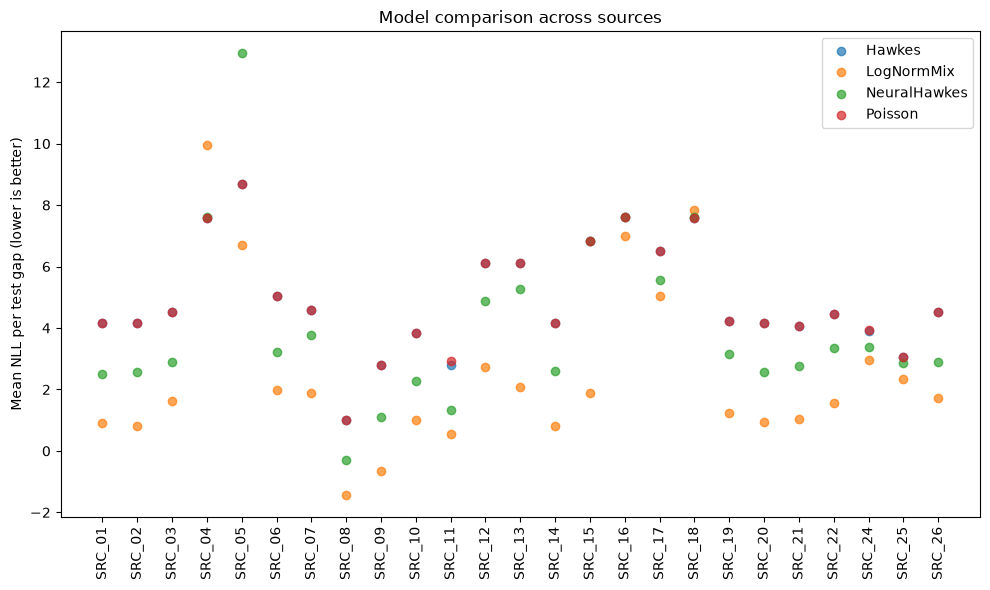

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))
for model_name, group in metrics_df.groupby("model"):
    ax.scatter(group["source_id"], group["mean_nll"], label=model_name, alpha=0.7)
ax.tick_params(axis="x", rotation=90)
ax.set_ylabel("Mean NLL per test gap (lower is better)")
ax.set_title("Model comparison across sources")
ax.legend()
plt.tight_layout()
plt.show()


### Notes for interpretation
- Poisson/Hawkes have no covariates by design (see Section 2/3 docstrings)
  — a gap where they underperform on a strongly calendar-driven source
  (e.g. SRC_03, SRC_06, SRC_07) is expected, not a bug.
- NeuralHawkes/LogNormMix results above use `use_calendar_features=True`
  by default — re-run Sections 4-5 with `use_calendar_features=False` to
  isolate how much of their advantage (if any) comes from covariates vs.
  from flexible sequence modeling alone.
- Neural models are trained with early stopping on the validation split
  (`training.MAX_EPOCHS`, `training.PATIENCE`, `training.LR`). The learning
  rate itself is still untuned — revisit in the Model/Metric Selection phase.
- The same pipeline runs headless via `arrivalcast run` from the
  project root.